# 09. 적정요금 세그먼트 기준 타당성 검증

**목적**: 신규 / 안정 / 프리미엄 세그먼트 기준이 데이터상 구조적으로 유의미한지 검증  
**검증 항목**:
1. 각 세그먼트의 RevPAR 구조적 차이
2. 가격 구간 기준의 수익 설명력
3. 리뷰 수 / 평점 / 슈퍼호스트 조건의 실제 분포
4. 세그먼트 간 겹침 정도
5. 전략적 활용 가능성 판단
+ 추가: 세그먼트 미분류(Uncovered) 비율 및 재정의 제안

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
from itertools import combinations
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 100

SEED = 42
np.random.seed(SEED)
print('라이브러리 로딩 완료')

라이브러리 로딩 완료


## 0. 데이터 로드 및 기본 전처리

In [2]:
df = pd.read_csv('../data/raw/seoul_airbnb_cleaned.csv')
print(f'전체 데이터: {df.shape[0]:,}행 × {df.shape[1]}열')
df[['ttm_avg_rate','ttm_revpar','num_reviews','rating_overall','superhost']].describe()

전체 데이터: 32,061행 × 42열


,ttm_avg_rate,ttm_revpar,num_reviews,rating_overall
count,3.206100e+04,32061.000000,32061.000000,32061.000000
mean,1.055178e+05,31309.895287,41.319984,3.977431
std,1.135290e+05,52454.103571,62.193910,1.708689
min,0.000000e+00,0.000000,0.000000,0.000000
25%,4.141968e+04,0.000000,6.000000,4.330000
50%,8.257587e+04,8868.300000,21.000000,4.730000
75%,1.337565e+05,45259.800000,52.000000,4.890000
max,1.981470e+06,830186.100000,3282.000000,5.000000


In [3]:
# Active+Operating 서브셋 (핵심 분석 대상)
df_ao = df[(df['refined_status']=='Active') & (df['operation_status']=='Operating')].copy()
print(f'Active+Operating 서브셋: {df_ao.shape[0]:,}행')

# ADR 유효값 필터 (0 초과, 이상치 제외)
adr_valid_mask = (df_ao['ttm_avg_rate'] > 0) & (df_ao['ttm_avg_rate'] <= 2_000_000)
df_ao = df_ao[adr_valid_mask].copy()
print(f'ADR 유효 필터 후: {df_ao.shape[0]:,}행')

# ADR 백분위 계산
p25 = df_ao['ttm_avg_rate'].quantile(0.25)
p50 = df_ao['ttm_avg_rate'].quantile(0.50)
p75 = df_ao['ttm_avg_rate'].quantile(0.75)
p25_lower = p25 * 0.85

print(f'\n[ADR 백분위]')
print(f'  p25*0.85 (신규 하한) = ₩{p25_lower:,.0f}')
print(f'  p25      (신규 상한 / 안정 하한) = ₩{p25:,.0f}')
print(f'  p50      (안정 상한 / 프리미엄 하한) = ₩{p50:,.0f}')
print(f'  p75      (프리미엄 상한) = ₩{p75:,.0f}')

Active+Operating 서브셋: 14,399행
ADR 유효 필터 후: 14,399행

[ADR 백분위]
  p25*0.85 (신규 하한) = ₩56,724
  p25      (신규 상한 / 안정 하한) = ₩66,734
  p50      (안정 상한 / 프리미엄 하한) = ₩102,321
  p75      (프리미엄 상한) = ₩154,036


In [4]:
# 세그먼트 분류 함수
def assign_segment(row):
    adr = row['ttm_avg_rate']
    reviews = row['num_reviews']
    rating = row['rating_overall']
    is_sh = row['superhost']

    if (p25_lower <= adr <= p25) and (reviews < 10):
        return '신규'
    elif (p25 <= adr <= p50) and (reviews >= 10) and (rating >= 4.5):
        return '안정'
    elif (p50 <= adr <= p75) and (is_sh == True or is_sh == 't' or str(is_sh).lower() == 'true') and (rating >= 4.8):
        return '프리미엄'
    else:
        return '미분류'

# superhost 값 확인
print('superhost 고유값:', df_ao['superhost'].unique()[:10])
print('superhost dtype:', df_ao['superhost'].dtype)

superhost 고유값: [ True False]
superhost dtype: bool


In [5]:
# superhost 정규화
if df_ao['superhost'].dtype == object:
    df_ao['superhost_bool'] = df_ao['superhost'].str.lower().map({'t': True, 'f': False, 'true': True, 'false': False})
else:
    df_ao['superhost_bool'] = df_ao['superhost'].astype(bool)

def assign_segment_v2(row):
    adr = row['ttm_avg_rate']
    reviews = row['num_reviews']
    rating = row['rating_overall']
    is_sh = row['superhost_bool']

    if (p25_lower <= adr <= p25) and (reviews < 10):
        return '신규'
    elif (p25 < adr <= p50) and (reviews >= 10) and (pd.notna(rating)) and (rating >= 4.5):
        return '안정'
    elif (p50 < adr <= p75) and (is_sh == True) and (pd.notna(rating)) and (rating >= 4.8):
        return '프리미엄'
    else:
        return '미분류'

df_ao['segment'] = df_ao.apply(assign_segment_v2, axis=1)

seg_counts = df_ao['segment'].value_counts()
print('[세그먼트 분포]')
for seg, cnt in seg_counts.items():
    pct = cnt / len(df_ao) * 100
    print(f'  {seg}: {cnt:,}개 ({pct:.1f}%)')

[세그먼트 분포]
  미분류: 9,572개 (66.5%)
  안정: 2,824개 (19.6%)
  프리미엄: 1,792개 (12.4%)
  신규: 211개 (1.5%)


## 1. 세그먼트별 RevPAR 구조 비교 (검증 ①)

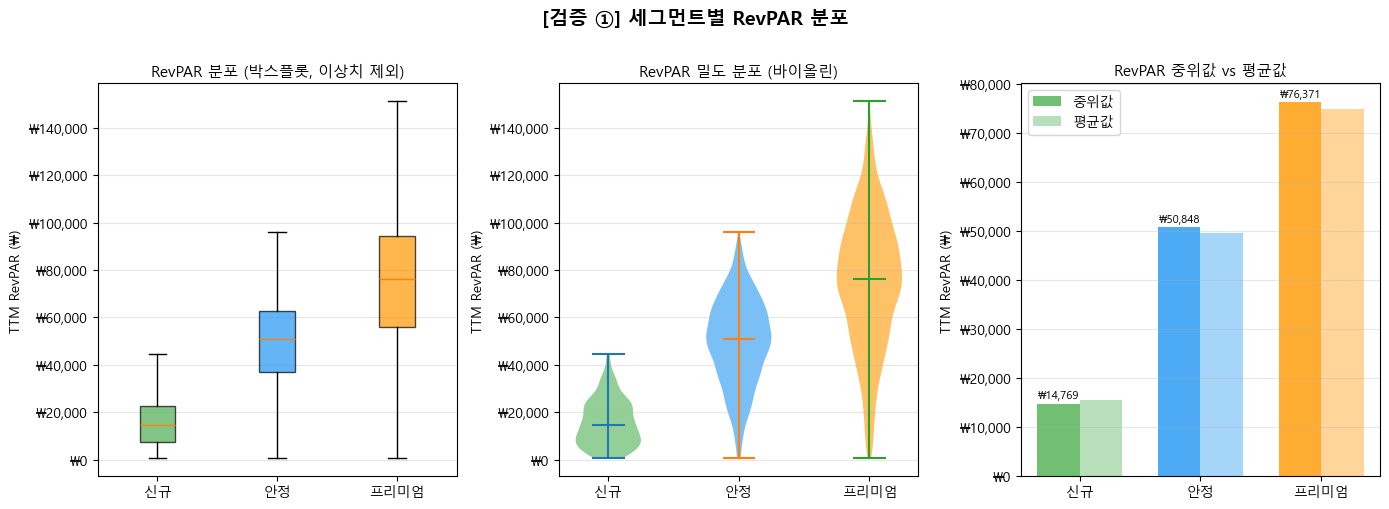


[RevPAR 기술통계]
          count     mean      std    min      25%      50%      75%       max
segment                                                                      
신규        211.0  15558.0   9820.0  565.0   7327.0  14769.0  22649.0   44378.0
안정       2824.0  49617.0  18449.0  523.0  36995.0  50848.0  62911.0   96295.0
프리미엄     1792.0  74975.0  28068.0  587.0  56097.0  76371.0  94342.0  151264.0


In [6]:
df_seg = df_ao[df_ao['segment'] != '미분류'].copy()
seg_order = ['신규', '안정', '프리미엄']
colors = {'신규': '#4CAF50', '안정': '#2196F3', '프리미엄': '#FF9800'}

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.suptitle('[검증 ①] 세그먼트별 RevPAR 분포', fontsize=14, fontweight='bold', y=1.01)

# 박스플롯
ax = axes[0]
data_box = [df_seg[df_seg['segment']==s]['ttm_revpar'].dropna() for s in seg_order]
bp = ax.boxplot(data_box, patch_artist=True, labels=seg_order, showfliers=False)
for patch, seg in zip(bp['boxes'], seg_order):
    patch.set_facecolor(colors[seg])
    patch.set_alpha(0.7)
ax.set_title('RevPAR 분포 (박스플롯, 이상치 제외)', fontsize=11)
ax.set_ylabel('TTM RevPAR (₩)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'₩{x:,.0f}'))
ax.grid(axis='y', alpha=0.3)

# 바이올린플롯
ax = axes[1]
for i, seg in enumerate(seg_order, 1):
    vals = df_seg[df_seg['segment']==seg]['ttm_revpar'].dropna()
    vp = ax.violinplot(vals, positions=[i], showmedians=True)
    for pc in vp['bodies']:
        pc.set_facecolor(colors[seg])
        pc.set_alpha(0.6)
ax.set_xticks([1,2,3])
ax.set_xticklabels(seg_order)
ax.set_title('RevPAR 밀도 분포 (바이올린)', fontsize=11)
ax.set_ylabel('TTM RevPAR (₩)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'₩{x:,.0f}'))
ax.grid(axis='y', alpha=0.3)

# 중위값/평균 비교 바차트
ax = axes[2]
stats_revpar = df_seg.groupby('segment')['ttm_revpar'].agg(['median','mean']).loc[seg_order]
x = np.arange(len(seg_order))
width = 0.35
bars1 = ax.bar(x - width/2, stats_revpar['median'], width, label='중위값', color=[colors[s] for s in seg_order], alpha=0.8)
bars2 = ax.bar(x + width/2, stats_revpar['mean'], width, label='평균값', color=[colors[s] for s in seg_order], alpha=0.4)
ax.set_xticks(x)
ax.set_xticklabels(seg_order)
ax.set_title('RevPAR 중위값 vs 평균값', fontsize=11)
ax.set_ylabel('TTM RevPAR (₩)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'₩{x:,.0f}'))
ax.legend()
ax.grid(axis='y', alpha=0.3)
for bar in bars1:
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+500, 
            f'₩{bar.get_height():,.0f}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig('../reports/fig_09_01_revpar_by_segment.png', bbox_inches='tight', dpi=100)
plt.show()
print()
print('[RevPAR 기술통계]')
print(df_seg.groupby('segment')['ttm_revpar'].describe(percentiles=[.25,.5,.75]).loc[seg_order].round(0).to_string())

In [7]:
# Kruskal-Wallis + 사후검정 (Dunn's test)
from scipy.stats import kruskal, mannwhitneyu

groups = [df_seg[df_seg['segment']==s]['ttm_revpar'].dropna() for s in seg_order]
stat, p = kruskal(*groups)
print(f'[Kruskal-Wallis 검정]')
print(f'  H-statistic = {stat:.2f}, p-value = {p:.4e}')
print(f'  결론: 세그먼트 간 RevPAR 중위값 차이가 {"통계적으로 유의함 (p<0.05)" if p < 0.05 else "유의하지 않음"}')
print()

print('[Mann-Whitney U 쌍별 비교]')
for s1, s2 in combinations(seg_order, 2):
    g1 = df_seg[df_seg['segment']==s1]['ttm_revpar'].dropna()
    g2 = df_seg[df_seg['segment']==s2]['ttm_revpar'].dropna()
    u, p_mw = mannwhitneyu(g1, g2, alternative='two-sided')
    med_diff = g2.median() - g1.median()
    pct_diff = med_diff / g1.median() * 100
    sig = '★ 유의' if p_mw < 0.05 else '비유의'
    print(f'  {s1} vs {s2}: p={p_mw:.4e} [{sig}] | 중위값 차이: ₩{med_diff:,.0f} ({pct_diff:+.1f}%)')

[Kruskal-Wallis 검정]
  H-statistic = 1419.80, p-value = 4.9556e-309
  결론: 세그먼트 간 RevPAR 중위값 차이가 통계적으로 유의함 (p<0.05)

[Mann-Whitney U 쌍별 비교]
  신규 vs 안정: p=6.8028e-101 [★ 유의] | 중위값 차이: ₩36,078 (+244.3%)
  신규 vs 프리미엄: p=3.4580e-110 [★ 유의] | 중위값 차이: ₩61,602 (+417.1%)
  안정 vs 프리미엄: p=1.5701e-220 [★ 유의] | 중위값 차이: ₩25,523 (+50.2%)


## 2. 가격 구간의 수익 설명력 (검증 ②)

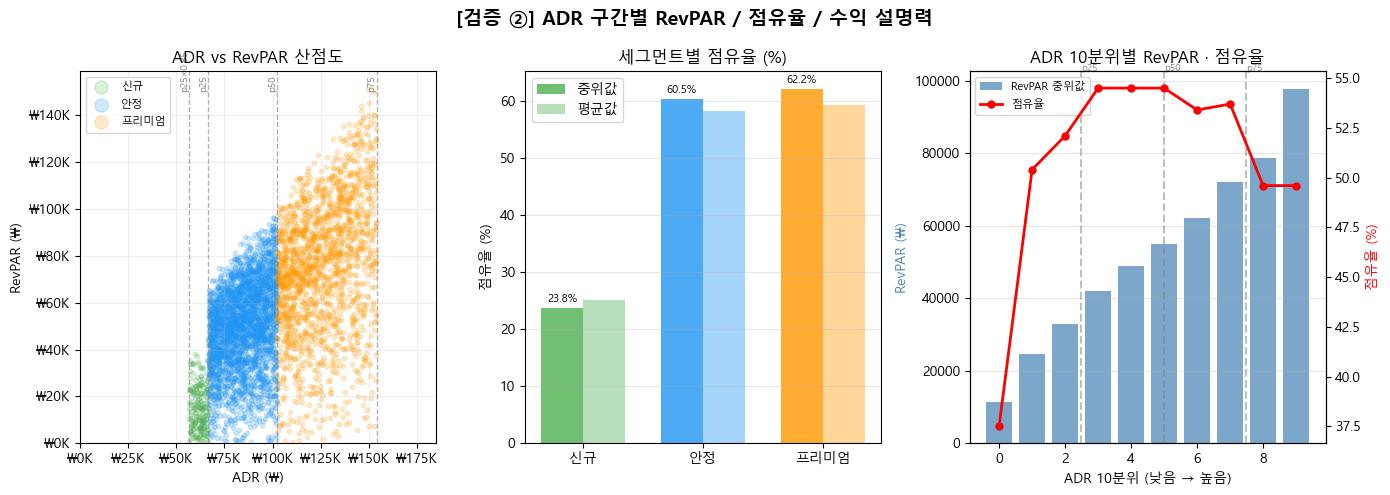

[ADR-RevPAR-점유율 상관관계 (Pearson)]
               ttm_avg_rate  ttm_revpar  ttm_occupancy
ttm_avg_rate          1.000       0.736          0.009
ttm_revpar            0.736       1.000          0.522
ttm_occupancy         0.009       0.522          1.000

Spearman(ADR, RevPAR) = 0.681, p = 0.0000e+00


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.suptitle('[검증 ②] ADR 구간별 RevPAR / 점유율 / 수익 설명력', fontsize=14, fontweight='bold')

# ADR vs RevPAR 산점도
ax = axes[0]
for seg in seg_order:
    sub = df_seg[df_seg['segment']==seg]
    ax.scatter(sub['ttm_avg_rate'], sub['ttm_revpar'], 
               alpha=0.2, s=10, label=seg, color=colors[seg])
# ADR 구간 경계선
for val, label in [(p25_lower,'p25×0.85'), (p25,'p25'), (p50,'p50'), (p75,'p75')]:
    ax.axvline(val, color='gray', linestyle='--', alpha=0.6, linewidth=1)
    ax.text(val, ax.get_ylim()[1]*0.95 if ax.get_ylim()[1] > 0 else 100000,
            label, rotation=90, ha='right', fontsize=7, color='gray')
ax.set_xlabel('ADR (₩)')
ax.set_ylabel('RevPAR (₩)')
ax.set_title('ADR vs RevPAR 산점도')
ax.legend(markerscale=3, fontsize=8)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'₩{x/1000:.0f}K'))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'₩{x/1000:.0f}K'))
ax.set_xlim(0, p75*1.2)
ax.set_ylim(0)
ax.grid(alpha=0.2)

# 세그먼트별 점유율 비교
ax = axes[1]
occ_stats = df_seg.groupby('segment')['ttm_occupancy'].agg(['median','mean']).loc[seg_order]
x = np.arange(len(seg_order))
width = 0.35
ax.bar(x - width/2, occ_stats['median']*100, width, label='중위값', color=[colors[s] for s in seg_order], alpha=0.8)
ax.bar(x + width/2, occ_stats['mean']*100, width, label='평균값', color=[colors[s] for s in seg_order], alpha=0.4)
ax.set_xticks(x)
ax.set_xticklabels(seg_order)
ax.set_title('세그먼트별 점유율 (%)')
ax.set_ylabel('점유율 (%)')
ax.legend()
ax.grid(axis='y', alpha=0.3)
for i, (_, row) in enumerate(occ_stats.iterrows()):
    ax.text(i - width/2, row['median']*100 + 0.5, f"{row['median']*100:.1f}%", ha='center', va='bottom', fontsize=8)

# ADR 구간별 RevPAR 분위수 히트맵
ax = axes[2]
# ADR 10분위로 나누어 RevPAR 중위값 계산
df_ao_valid = df_ao[df_ao['ttm_avg_rate'] <= p75*1.5].copy()
df_ao_valid['adr_decile'] = pd.qcut(df_ao_valid['ttm_avg_rate'], q=10, labels=False)
decile_stats = df_ao_valid.groupby('adr_decile').agg(
    adr_med=('ttm_avg_rate','median'),
    revpar_med=('ttm_revpar','median'),
    occ_med=('ttm_occupancy','median')
).reset_index()
ax2_twin = ax.twinx()
ax.bar(decile_stats['adr_decile'], decile_stats['revpar_med'], color='steelblue', alpha=0.7, label='RevPAR 중위값')
ax2_twin.plot(decile_stats['adr_decile'], decile_stats['occ_med']*100, 'ro-', label='점유율', linewidth=2, markersize=5)
ax.set_xlabel('ADR 10분위 (낮음 → 높음)')
ax.set_ylabel('RevPAR (₩)', color='steelblue')
ax2_twin.set_ylabel('점유율 (%)', color='red')
ax.set_title('ADR 10분위별 RevPAR · 점유율')
# 구간 경계 표시
for pval, pname in [(p25,'p25'),(p50,'p50'),(p75,'p75')]:
    pctile_idx = (df_ao_valid['ttm_avg_rate'] <= pval).sum() / len(df_ao_valid) * 9
    ax.axvline(pctile_idx, color='gray', linestyle='--', alpha=0.5)
    ax.text(pctile_idx, ax.get_ylim()[1] if ax.get_ylim()[1]>0 else 50000, pname, fontsize=7, color='gray')
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2_twin.get_legend_handles_labels()
ax.legend(lines1+lines2, labels1+labels2, fontsize=8, loc='upper left')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('../reports/fig_09_02_adr_revpar_explanation.png', bbox_inches='tight', dpi=100)
plt.show()

# 상관계수 출력
corr_adr_revpar = df_ao[['ttm_avg_rate','ttm_revpar','ttm_occupancy']].corr()
print('[ADR-RevPAR-점유율 상관관계 (Pearson)]')
print(corr_adr_revpar.round(3).to_string())
print()
sp_corr, sp_p = stats.spearmanr(df_ao['ttm_avg_rate'].dropna(), df_ao['ttm_revpar'].dropna())
print(f'Spearman(ADR, RevPAR) = {sp_corr:.3f}, p = {sp_p:.4e}')

## 3. 세그먼트 자격 조건의 실제 분포 (검증 ③)

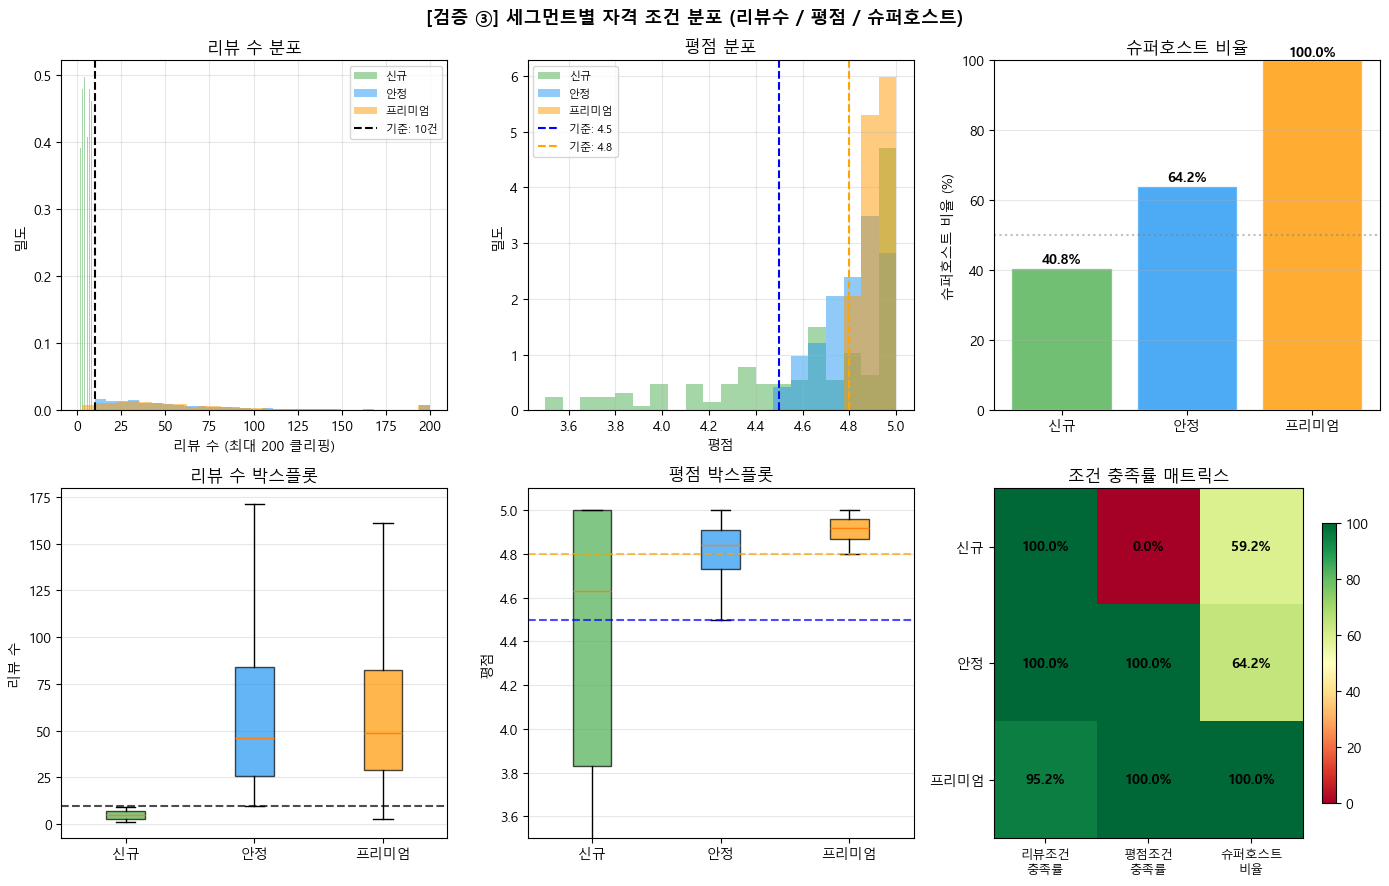

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(14, 9))
fig.suptitle('[검증 ③] 세그먼트별 자격 조건 분포 (리뷰수 / 평점 / 슈퍼호스트)', 
             fontsize=13, fontweight='bold')

# 3-1. 세그먼트별 리뷰 수 분포
ax = axes[0,0]
for seg in seg_order:
    vals = df_seg[df_seg['segment']==seg]['num_reviews'].clip(upper=200)
    ax.hist(vals, bins=30, alpha=0.5, label=seg, color=colors[seg], density=True)
ax.axvline(10, color='black', linestyle='--', linewidth=1.5, label='기준: 10건')
ax.set_xlabel('리뷰 수 (최대 200 클리핑)')
ax.set_ylabel('밀도')
ax.set_title('리뷰 수 분포')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

# 3-2. 세그먼트별 평점 분포
ax = axes[0,1]
for seg in seg_order:
    vals = df_seg[df_seg['segment']==seg]['rating_overall'].dropna()
    ax.hist(vals, bins=20, alpha=0.5, label=seg, color=colors[seg], density=True, range=(3.5,5.0))
ax.axvline(4.5, color='blue', linestyle='--', linewidth=1.5, label='기준: 4.5')
ax.axvline(4.8, color='orange', linestyle='--', linewidth=1.5, label='기준: 4.8')
ax.set_xlabel('평점')
ax.set_ylabel('밀도')
ax.set_title('평점 분포')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

# 3-3. 슈퍼호스트 비율 by 세그먼트
ax = axes[0,2]
sh_rates = df_seg.groupby('segment')['superhost_bool'].mean().loc[seg_order] * 100
bars = ax.bar(seg_order, sh_rates, color=[colors[s] for s in seg_order], alpha=0.8, edgecolor='white')
for bar, val in zip(bars, sh_rates):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
            f'{val:.1f}%', ha='center', va='bottom', fontweight='bold')
ax.set_ylabel('슈퍼호스트 비율 (%)')
ax.set_title('슈퍼호스트 비율')
ax.set_ylim(0, 100)
ax.axhline(50, color='gray', linestyle=':', alpha=0.5)
ax.grid(axis='y', alpha=0.3)

# 3-4. 세그먼트별 리뷰 수 박스플롯 (로그 스케일)
ax = axes[1,0]
data_rev = [df_seg[df_seg['segment']==s]['num_reviews'].clip(upper=300) for s in seg_order]
bp = ax.boxplot(data_rev, patch_artist=True, labels=seg_order, showfliers=False)
for patch, seg in zip(bp['boxes'], seg_order):
    patch.set_facecolor(colors[seg])
    patch.set_alpha(0.7)
ax.axhline(10, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
ax.set_ylabel('리뷰 수')
ax.set_title('리뷰 수 박스플롯')
ax.grid(axis='y', alpha=0.3)

# 3-5. 세그먼트별 평점 박스플롯
ax = axes[1,1]
data_rat = [df_seg[df_seg['segment']==s]['rating_overall'].dropna() for s in seg_order]
bp = ax.boxplot(data_rat, patch_artist=True, labels=seg_order, showfliers=True,
                flierprops=dict(marker='o', markersize=2, alpha=0.3))
for patch, seg in zip(bp['boxes'], seg_order):
    patch.set_facecolor(colors[seg])
    patch.set_alpha(0.7)
ax.axhline(4.5, color='blue', linestyle='--', linewidth=1.5, alpha=0.7)
ax.axhline(4.8, color='orange', linestyle='--', linewidth=1.5, alpha=0.7)
ax.set_ylabel('평점')
ax.set_ylim(3.5, 5.1)
ax.set_title('평점 박스플롯')
ax.grid(axis='y', alpha=0.3)

# 3-6. 세그먼트별 조건 충족률 정리표 (히트맵)
ax = axes[1,2]
condition_data = {}
# 신규: ADR 구간 내, 리뷰<10
seg_신규 = df_seg[df_seg['segment']=='신규']
seg_안정 = df_seg[df_seg['segment']=='안정']
seg_프리미엄 = df_seg[df_seg['segment']=='프리미엄']

condition_matrix = np.array([
    # 신규
    [
        ((seg_신규['num_reviews'] < 10).mean()*100),  # 리뷰<10 충족
        (seg_신규['rating_overall'].isna().mean()*100),  # 평점 없음 비율
        (seg_신규['superhost_bool']==False).mean()*100,  # 비슈퍼호스트 비율
    ],
    # 안정
    [
        ((seg_안정['num_reviews'] >= 10).mean()*100),
        ((seg_안정['rating_overall'] >= 4.5).mean()*100),
        (seg_안정['superhost_bool']==True).mean()*100,
    ],
    # 프리미엄
    [
        ((seg_프리미엄['num_reviews'] >= 10).mean()*100),
        ((seg_프리미엄['rating_overall'] >= 4.8).mean()*100),
        (seg_프리미엄['superhost_bool']==True).mean()*100,
    ],
])

im = ax.imshow(condition_matrix, cmap='RdYlGn', vmin=0, vmax=100, aspect='auto')
ax.set_xticks([0,1,2])
ax.set_xticklabels(['리뷰조건\n충족률', '평점조건\n충족률', '슈퍼호스트\n비율'], fontsize=9)
ax.set_yticks([0,1,2])
ax.set_yticklabels(seg_order)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f'{condition_matrix[i,j]:.1f}%', ha='center', va='center', 
                fontweight='bold', fontsize=10, color='black')
ax.set_title('조건 충족률 매트릭스')
plt.colorbar(im, ax=ax, shrink=0.8)

plt.tight_layout()
plt.savefig('../reports/fig_09_03_condition_distribution.png', bbox_inches='tight', dpi=100)
plt.show()

In [10]:
# 조건별 통계 요약
print('='*60)
print('[세그먼트별 조건 충족 상세]')
print('='*60)

print('\n■ 신규 세그먼트')
print(f"  리뷰 < 10건: {(seg_신규['num_reviews'] < 10).mean()*100:.1f}% (정의상 100% 예상)")
print(f"  평점 없음(NA): {seg_신규['rating_overall'].isna().mean()*100:.1f}%")
print(f"  슈퍼호스트: {seg_신규['superhost_bool'].mean()*100:.1f}%")
print(f"  RevPAR 중위값: ₩{seg_신규['ttm_revpar'].median():,.0f}")

print('\n■ 안정 세그먼트')
print(f"  리뷰 ≥ 10건: {(seg_안정['num_reviews'] >= 10).mean()*100:.1f}%")
print(f"  평점 ≥ 4.5: {(seg_안정['rating_overall'] >= 4.5).mean()*100:.1f}%")
print(f"  슈퍼호스트: {seg_안정['superhost_bool'].mean()*100:.1f}%")
print(f"  RevPAR 중위값: ₩{seg_안정['ttm_revpar'].median():,.0f}")

print('\n■ 프리미엄 세그먼트')
print(f"  리뷰 ≥ 10건: {(seg_프리미엄['num_reviews'] >= 10).mean()*100:.1f}%")
print(f"  평점 ≥ 4.8: {(seg_프리미엄['rating_overall'] >= 4.8).mean()*100:.1f}%")
print(f"  슈퍼호스트: {seg_프리미엄['superhost_bool'].mean()*100:.1f}%")
print(f"  RevPAR 중위값: ₩{seg_프리미엄['ttm_revpar'].median():,.0f}")

[세그먼트별 조건 충족 상세]

■ 신규 세그먼트
  리뷰 < 10건: 100.0% (정의상 100% 예상)
  평점 없음(NA): 0.0%
  슈퍼호스트: 40.8%
  RevPAR 중위값: ₩14,769

■ 안정 세그먼트
  리뷰 ≥ 10건: 100.0%
  평점 ≥ 4.5: 100.0%
  슈퍼호스트: 64.2%
  RevPAR 중위값: ₩50,848

■ 프리미엄 세그먼트
  리뷰 ≥ 10건: 95.2%
  평점 ≥ 4.8: 100.0%
  슈퍼호스트: 100.0%
  RevPAR 중위값: ₩76,371


## 4. 세그먼트 간 겹침 분석 (검증 ④)

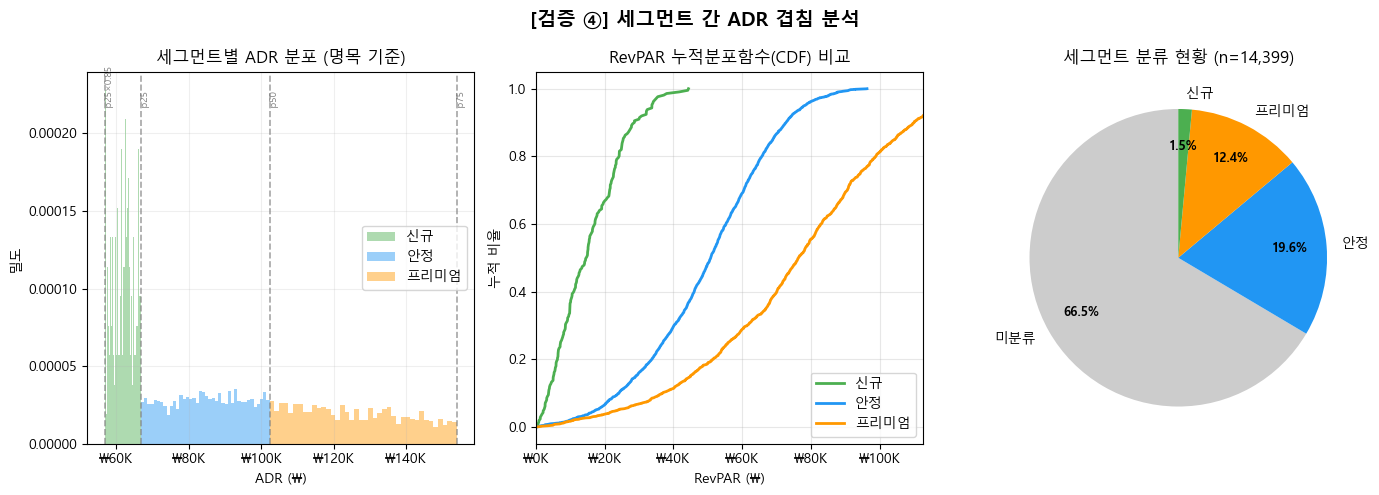

[세그먼트별 RevPAR IQR 겹침 분석]
  신규: IQR = [₩7,327, ₩22,649]
  안정: IQR = [₩36,995, ₩62,911]
  프리미엄: IQR = [₩56,097, ₩94,342]


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.suptitle('[검증 ④] 세그먼트 간 ADR 겹침 분석', fontsize=14, fontweight='bold')

# ADR 분포 겹침 시각화
ax = axes[0]
for seg in seg_order:
    vals = df_seg[df_seg['segment']==seg]['ttm_avg_rate'].clip(upper=p75*1.5)
    ax.hist(vals, bins=40, alpha=0.45, label=seg, color=colors[seg], density=True)
for val, label in [(p25_lower,'p25×0.85'), (p25,'p25'), (p50,'p50'), (p75,'p75')]:
    ax.axvline(val, color='gray', linestyle='--', alpha=0.7, linewidth=1.2)
    ax.text(val, ax.get_ylim()[1]*0.9 if ax.get_ylim()[1]>0 else 0.00001, 
            f' {label}', fontsize=7, color='gray', rotation=90)
ax.set_xlabel('ADR (₩)')
ax.set_ylabel('밀도')
ax.set_title('세그먼트별 ADR 분포 (명목 기준)')
ax.legend()
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'₩{x/1000:.0f}K'))
ax.grid(alpha=0.2)

# RevPAR CDF 겹침
ax = axes[1]
for seg in seg_order:
    vals = np.sort(df_seg[df_seg['segment']==seg]['ttm_revpar'].dropna())
    cdf = np.arange(1, len(vals)+1) / len(vals)
    ax.plot(vals, cdf, label=seg, color=colors[seg], linewidth=2)
ax.set_xlabel('RevPAR (₩)')
ax.set_ylabel('누적 비율')
ax.set_title('RevPAR 누적분포함수(CDF) 비교')
ax.set_xlim(0, df_seg['ttm_revpar'].quantile(0.97))
ax.legend()
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'₩{x/1000:.0f}K'))
ax.grid(alpha=0.3)

# 미분류 분석
ax = axes[2]
seg_all = df_ao['segment'].value_counts()
pie_colors = [colors.get(s, '#CCCCCC') for s in seg_all.index]
wedges, texts, autotexts = ax.pie(
    seg_all.values, 
    labels=seg_all.index, 
    colors=pie_colors,
    autopct='%1.1f%%',
    startangle=90,
    pctdistance=0.75
)
for at in autotexts:
    at.set_fontsize(9)
    at.set_fontweight('bold')
ax.set_title(f'세그먼트 분류 현황 (n={len(df_ao):,})')

plt.tight_layout()
plt.savefig('../reports/fig_09_04_segment_overlap.png', bbox_inches='tight', dpi=100)
plt.show()

# RevPAR 겹침 정량화 (IQR 기반)
print('[세그먼트별 RevPAR IQR 겹침 분석]')
for seg in seg_order:
    vals = df_seg[df_seg['segment']==seg]['ttm_revpar'].dropna()
    q1, q3 = vals.quantile(0.25), vals.quantile(0.75)
    print(f'  {seg}: IQR = [₩{q1:,.0f}, ₩{q3:,.0f}]')

In [12]:
# 겹침 정량화: 세그먼트 쌍별 RevPAR 분포 중첩 계산 (Overlap Coefficient)
from scipy.stats import gaussian_kde

def overlap_coefficient(a, b, num_points=1000):
    """두 분포의 오버랩 계수 계산 (0=완전분리, 1=완전겹침)"""
    a, b = a.dropna(), b.dropna()
    min_val = min(a.min(), b.min())
    max_val = max(a.quantile(0.99), b.quantile(0.99))
    x = np.linspace(min_val, max_val, num_points)
    kde_a = gaussian_kde(a)(x)
    kde_b = gaussian_kde(b)(x)
    overlap = np.minimum(kde_a, kde_b).sum() / max(kde_a.sum(), kde_b.sum())
    return overlap

print('[RevPAR 분포 겹침 계수 (0=완전분리, 1=완전겹침)]')
for s1, s2 in combinations(seg_order, 2):
    v1 = df_seg[df_seg['segment']==s1]['ttm_revpar'].dropna()
    v2 = df_seg[df_seg['segment']==s2]['ttm_revpar'].dropna()
    oc = overlap_coefficient(v1, v2)
    verdict = '✓ 양호(분리됨)' if oc < 0.5 else ('△ 보통' if oc < 0.7 else '✗ 과도한 겹침')
    print(f'  {s1} ↔ {s2}: Overlap = {oc:.3f} [{verdict}]')

[RevPAR 분포 겹침 계수 (0=완전분리, 1=완전겹침)]
  신규 ↔ 안정: Overlap = 0.258 [✓ 양호(분리됨)]
  신규 ↔ 프리미엄: Overlap = 0.131 [✓ 양호(분리됨)]
  안정 ↔ 프리미엄: Overlap = 0.545 [△ 보통]


## 5. 미분류 리스팅 심층 분석 (추가 검증)

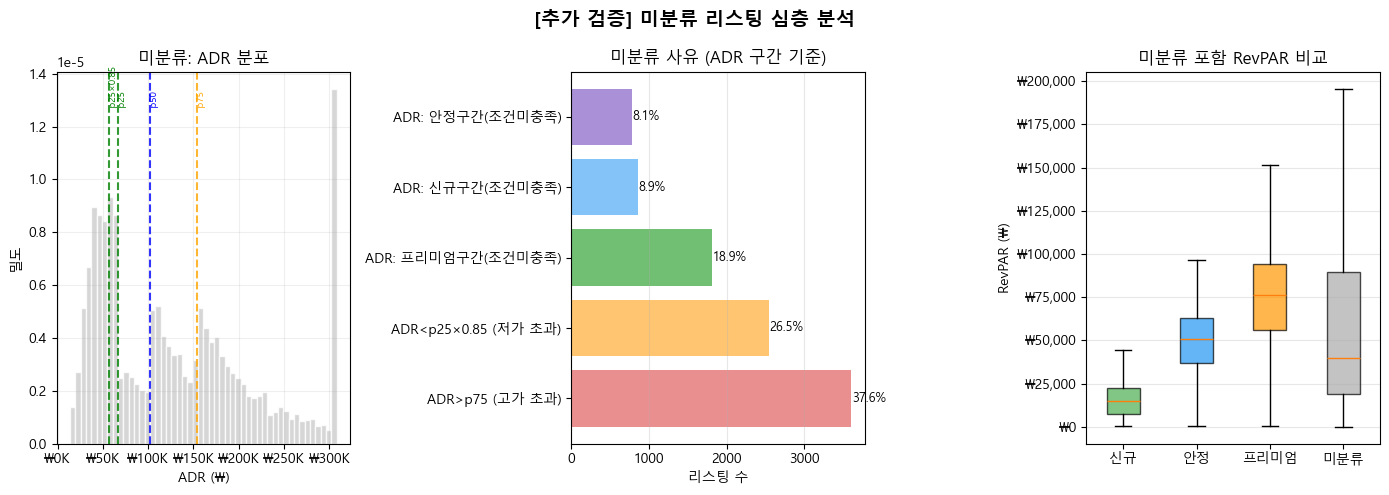

[미분류 리스팅 주요 통계]
  전체 미분류: 9,572개 (66.5%)
  미분류 RevPAR 중위값: ₩39,793
  미분류 ADR 중위값: ₩114,751

[미분류 ADR 구간 분포]
  ADR>p75 (고가 초과): 3,600개 (37.6%)
  ADR<p25×0.85 (저가 초과): 2,538개 (26.5%)
  ADR: 프리미엄구간(조건미충족): 1,807개 (18.9%)
  ADR: 신규구간(조건미충족): 851개 (8.9%)
  ADR: 안정구간(조건미충족): 776개 (8.1%)


In [13]:
df_unclassified = df_ao[df_ao['segment'] == '미분류'].copy()

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.suptitle('[추가 검증] 미분류 리스팅 심층 분석', fontsize=14, fontweight='bold')

# 미분류의 ADR 분포 — 어느 구간에 위치?
ax = axes[0]
ax.hist(df_unclassified['ttm_avg_rate'].clip(upper=p75*2), bins=50, 
        color='#CCCCCC', edgecolor='white', alpha=0.8, density=True)
for val, label, clr in [(p25_lower,'p25×0.85','green'), (p25,'p25','green'), 
                         (p50,'p50','blue'), (p75,'p75','orange')]:
    ax.axvline(val, color=clr, linestyle='--', alpha=0.8, linewidth=1.5)
    ax.text(val, ax.get_ylim()[1]*0.9 if ax.get_ylim()[1]>0 else 0.00001,
            f' {label}', fontsize=7, color=clr, rotation=90)
ax.set_xlabel('ADR (₩)')
ax.set_ylabel('밀도')
ax.set_title('미분류: ADR 분포')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'₩{x/1000:.0f}K'))
ax.grid(alpha=0.2)

# 미분류가 미분류된 이유 분석 (조건 미충족 사유)
ax = axes[1]
# ADR 구간별로 어디에 속하는지
def adr_zone(adr):
    if adr < p25_lower: return 'ADR<p25×0.85 (저가 초과)'
    elif adr <= p25: return 'ADR: 신규구간(조건미충족)'
    elif adr <= p50: return 'ADR: 안정구간(조건미충족)'
    elif adr <= p75: return 'ADR: 프리미엄구간(조건미충족)'
    else: return 'ADR>p75 (고가 초과)'

df_unclassified['adr_zone'] = df_unclassified['ttm_avg_rate'].apply(adr_zone)
zone_counts = df_unclassified['adr_zone'].value_counts()
zone_pcts = zone_counts / len(df_unclassified) * 100
colors_zone = ['#E57373','#FFB74D','#4CAF50','#64B5F6','#9575CD']
bars = ax.barh(zone_counts.index, zone_counts.values, color=colors_zone[:len(zone_counts)], alpha=0.8)
for bar, pct in zip(bars, zone_pcts):
    ax.text(bar.get_width()+10, bar.get_y()+bar.get_height()/2,
            f'{pct:.1f}%', va='center', fontsize=9)
ax.set_xlabel('리스팅 수')
ax.set_title('미분류 사유 (ADR 구간 기준)')
ax.grid(axis='x', alpha=0.3)

# 미분류 vs 세그먼트 RevPAR 비교
ax = axes[2]
all_segs = seg_order + ['미분류']
all_colors = [colors[s] for s in seg_order] + ['#AAAAAA']
all_data = [df_ao[df_ao['segment']==s]['ttm_revpar'].dropna() for s in all_segs]
bp = ax.boxplot(all_data, patch_artist=True, labels=all_segs, showfliers=False)
for patch, clr in zip(bp['boxes'], all_colors):
    patch.set_facecolor(clr)
    patch.set_alpha(0.7)
ax.set_ylabel('RevPAR (₩)')
ax.set_title('미분류 포함 RevPAR 비교')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'₩{x:,.0f}'))
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('../reports/fig_09_05_unclassified_analysis.png', bbox_inches='tight', dpi=100)
plt.show()

print('[미분류 리스팅 주요 통계]')
print(f'  전체 미분류: {len(df_unclassified):,}개 ({len(df_unclassified)/len(df_ao)*100:.1f}%)')
print(f'  미분류 RevPAR 중위값: ₩{df_unclassified["ttm_revpar"].median():,.0f}')
print(f'  미분류 ADR 중위값: ₩{df_unclassified["ttm_avg_rate"].median():,.0f}')
print()
print('[미분류 ADR 구간 분포]')
for zone, cnt in zone_counts.items():
    print(f'  {zone}: {cnt:,}개 ({cnt/len(df_unclassified)*100:.1f}%)')

## 6. 세그먼트 내부 이질성 및 RevPAR 설명력 정량화 (추가 검증)

In [14]:
# Effect Size (Cohen's d) 계산
def cohens_d(a, b):
    a, b = a.dropna(), b.dropna()
    pooled_std = np.sqrt(((len(a)-1)*a.std()**2 + (len(b)-1)*b.std()**2) / (len(a)+len(b)-2))
    return (a.mean() - b.mean()) / pooled_std if pooled_std > 0 else 0

# 분산분석으로 세그먼트 설명력 확인 (Eta squared)
from scipy.stats import f_oneway

groups = [df_seg[df_seg['segment']==s]['ttm_revpar'].dropna() for s in seg_order]
f_stat, p_val = f_oneway(*groups)

grand_mean = df_seg['ttm_revpar'].mean()
ss_between = sum(len(g) * (g.mean() - grand_mean)**2 for g in groups)
ss_total = sum((df_seg['ttm_revpar'].dropna() - grand_mean)**2)
eta_sq = ss_between / ss_total

print('[분산분석 (ANOVA) 결과]')
print(f'  F-statistic = {f_stat:.2f}, p-value = {p_val:.4e}')
print(f'  η² (Eta-squared) = {eta_sq:.4f}')
print(f'  해석: 세그먼트 변수가 RevPAR 분산의 {eta_sq*100:.1f}%를 설명')
print(f'  기준: η² > 0.14 → 큰 효과크기')
print()

print('[Cohen\'s d (효과 크기)]')
for s1, s2 in combinations(seg_order, 2):
    v1 = df_seg[df_seg['segment']==s1]['ttm_revpar']
    v2 = df_seg[df_seg['segment']==s2]['ttm_revpar']
    d = cohens_d(v1, v2)
    magnitude = 'small' if abs(d) < 0.5 else ('medium' if abs(d) < 0.8 else 'large')
    print(f'  {s1} vs {s2}: d = {d:.2f} [{magnitude}]')

[분산분석 (ANOVA) 결과]
  F-statistic = 1103.00, p-value = 0.0000e+00
  η² (Eta-squared) = 0.3138
  해석: 세그먼트 변수가 RevPAR 분산의 31.4%를 설명
  기준: η² > 0.14 → 큰 효과크기

[Cohen's d (효과 크기)]
  신규 vs 안정: d = -1.89 [large]
  신규 vs 프리미엄: d = -2.22 [large]
  안정 vs 프리미엄: d = -1.12 [large]


In [15]:
# 세그먼트 내부 이질성: CV (변동계수)
print('[세그먼트 내부 이질성 — 변동계수 (CV = σ/μ, 낮을수록 균질)]')
for seg in seg_order:
    vals = df_seg[df_seg['segment']==seg]['ttm_revpar'].dropna()
    cv = vals.std() / vals.mean()
    gini = vals.sort_values().reset_index(drop=True)
    n = len(gini)
    gini_coef = (2 * sum((i+1)*v for i,v in enumerate(gini)) / (n * gini.sum())) - (n+1)/n
    print(f'  {seg}: 평균=₩{vals.mean():,.0f}, CV={cv:.2f}, Gini={gini_coef:.3f}')

print()
# 로그 RevPAR로 동일 분석
print('[log1p(RevPAR) 기준 세그먼트 설명력]')
df_seg['log_revpar'] = np.log1p(df_seg['ttm_revpar'])
groups_log = [df_seg[df_seg['segment']==s]['log_revpar'].dropna() for s in seg_order]
f2, p2 = f_oneway(*groups_log)
grand_mean_log = df_seg['log_revpar'].mean()
ss_b = sum(len(g)*(g.mean()-grand_mean_log)**2 for g in groups_log)
ss_t = sum((df_seg['log_revpar'].dropna()-grand_mean_log)**2)
eta2_log = ss_b / ss_t
print(f'  F={f2:.2f}, p={p2:.4e}, η²={eta2_log:.4f} (RevPAR 분산의 {eta2_log*100:.1f}% 설명)')

[세그먼트 내부 이질성 — 변동계수 (CV = σ/μ, 낮을수록 균질)]
  신규: 평균=₩15,558, CV=0.63, Gini=0.356
  안정: 평균=₩49,617, CV=0.37, Gini=0.211
  프리미엄: 평균=₩74,975, CV=0.37, Gini=0.212

[log1p(RevPAR) 기준 세그먼트 설명력]
  F=977.99, p=0.0000e+00, η²=0.2885 (RevPAR 분산의 28.8% 설명)


## 7. 세그먼트 기준 민감도 분석 (추가 검증)

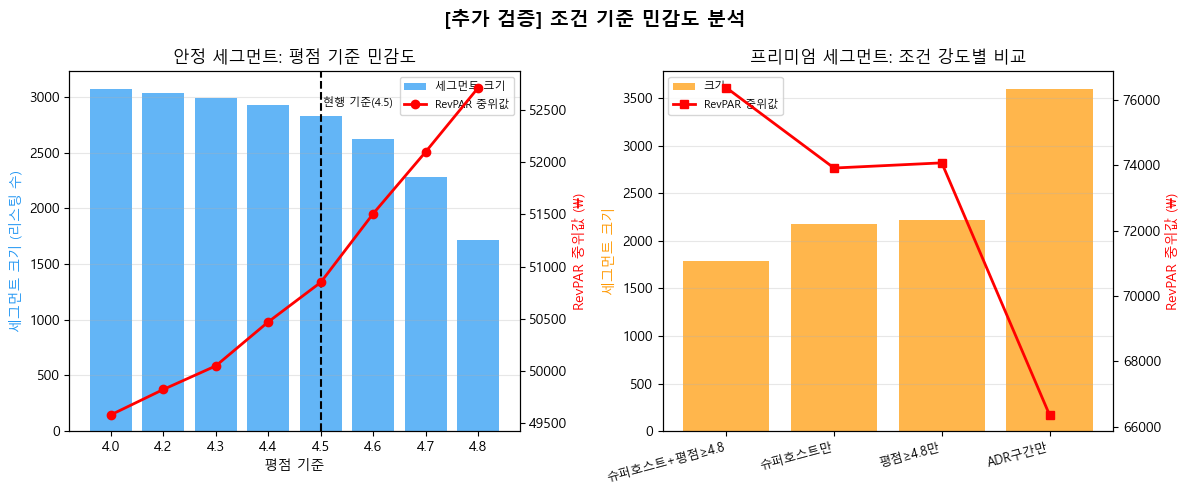

In [16]:
# 평점 기준 변경 시 세그먼트 크기 변화
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('[추가 검증] 조건 기준 민감도 분석', fontsize=14, fontweight='bold')

# 안정 세그먼트: 평점 기준 변화에 따른 크기
ax = axes[0]
rating_thresholds = [4.0, 4.2, 4.3, 4.4, 4.5, 4.6, 4.7, 4.8]
stable_adr_mask = (df_ao['ttm_avg_rate'] > p25) & (df_ao['ttm_avg_rate'] <= p50)
review_mask = df_ao['num_reviews'] >= 10

stable_sizes = []
stable_revpar_meds = []
for thresh in rating_thresholds:
    rating_mask = df_ao['rating_overall'] >= thresh
    size = (stable_adr_mask & review_mask & rating_mask).sum()
    revpar_med = df_ao[stable_adr_mask & review_mask & rating_mask]['ttm_revpar'].median()
    stable_sizes.append(size)
    stable_revpar_meds.append(revpar_med)

ax2 = ax.twinx()
ax.bar(range(len(rating_thresholds)), stable_sizes, color='#2196F3', alpha=0.7, label='세그먼트 크기')
ax2.plot(range(len(rating_thresholds)), stable_revpar_meds, 'ro-', linewidth=2, label='RevPAR 중위값')
ax.axvline(rating_thresholds.index(4.5), color='black', linestyle='--', linewidth=1.5)
ax.text(rating_thresholds.index(4.5)+0.05, max(stable_sizes)*0.95, '현행 기준(4.5)', fontsize=8)
ax.set_xticks(range(len(rating_thresholds)))
ax.set_xticklabels(rating_thresholds)
ax.set_xlabel('평점 기준')
ax.set_ylabel('세그먼트 크기 (리스팅 수)', color='#2196F3')
ax2.set_ylabel('RevPAR 중위값 (₩)', color='red')
ax.set_title('안정 세그먼트: 평점 기준 민감도')
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1+lines2, labels1+labels2, fontsize=8)
ax.grid(axis='y', alpha=0.3)

# 프리미엄 세그먼트: 슈퍼호스트 조건 유무에 따른 차이
ax = axes[1]
premium_adr_mask = (df_ao['ttm_avg_rate'] > p50) & (df_ao['ttm_avg_rate'] <= p75)

conditions = [
    ('슈퍼호스트+평점≥4.8', premium_adr_mask & (df_ao['superhost_bool']==True) & (df_ao['rating_overall']>=4.8)),
    ('슈퍼호스트만', premium_adr_mask & (df_ao['superhost_bool']==True)),
    ('평점≥4.8만', premium_adr_mask & (df_ao['rating_overall']>=4.8)),
    ('ADR구간만', premium_adr_mask),
]

cond_labels = [c[0] for c in conditions]
cond_sizes = [c[1].sum() for c in conditions]
cond_revpar = [df_ao[c[1]]['ttm_revpar'].median() for c in conditions]

x = np.arange(len(conditions))
ax2b = ax.twinx()
ax.bar(x, cond_sizes, color='#FF9800', alpha=0.7, label='크기')
ax2b.plot(x, cond_revpar, 'rs-', linewidth=2, label='RevPAR 중위값')
ax.set_xticks(x)
ax.set_xticklabels(cond_labels, rotation=15, ha='right', fontsize=9)
ax.set_ylabel('세그먼트 크기', color='#FF9800')
ax2b.set_ylabel('RevPAR 중위값 (₩)', color='red')
ax.set_title('프리미엄 세그먼트: 조건 강도별 비교')
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2b.get_legend_handles_labels()
ax.legend(lines1+lines2, labels1+labels2, fontsize=8)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('../reports/fig_09_06_sensitivity_analysis.png', bbox_inches='tight', dpi=100)
plt.show()

## 8. 종합 검증 대시보드

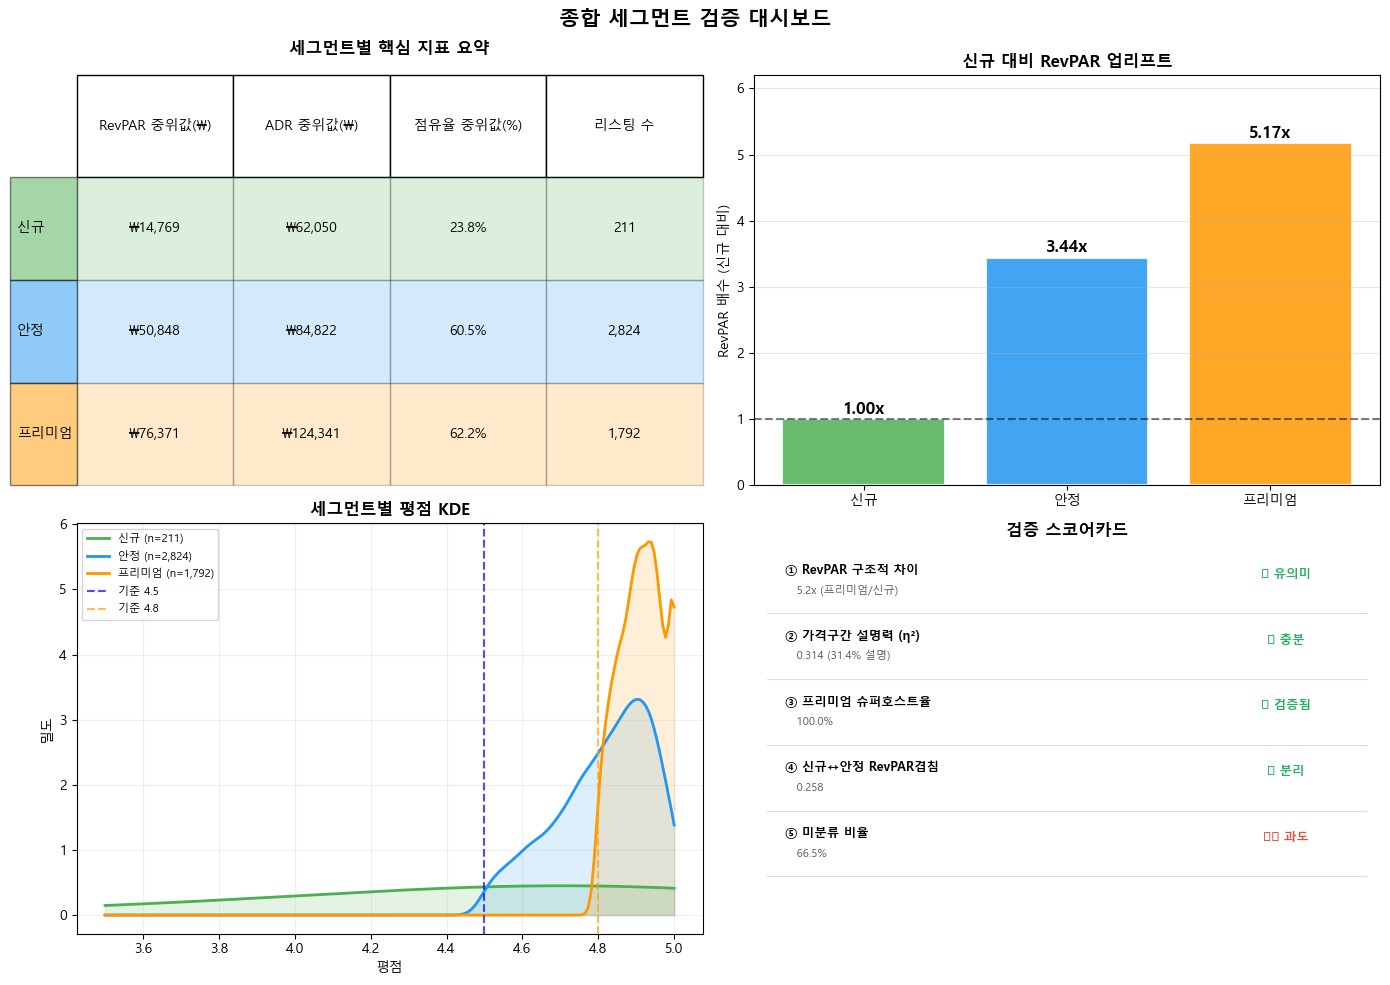

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('종합 세그먼트 검증 대시보드', fontsize=15, fontweight='bold')

# (1) 세그먼트별 RevPAR 핵심 지표
ax = axes[0,0]
metrics = {
    '신규': {
        'revpar_med': seg_신규['ttm_revpar'].median(),
        'adr_med': seg_신규['ttm_avg_rate'].median(),
        'occ_med': seg_신규['ttm_occupancy'].median()*100,
        'count': len(seg_신규)
    },
    '안정': {
        'revpar_med': seg_안정['ttm_revpar'].median(),
        'adr_med': seg_안정['ttm_avg_rate'].median(),
        'occ_med': seg_안정['ttm_occupancy'].median()*100,
        'count': len(seg_안정)
    },
    '프리미엄': {
        'revpar_med': seg_프리미엄['ttm_revpar'].median(),
        'adr_med': seg_프리미엄['ttm_avg_rate'].median(),
        'occ_med': seg_프리미엄['ttm_occupancy'].median()*100,
        'count': len(seg_프리미엄)
    }
}

metric_names = ['RevPAR 중위값(₩)', 'ADR 중위값(₩)', '점유율 중위값(%)', '리스팅 수']
table_data = []
for seg in seg_order:
    m = metrics[seg]
    table_data.append([
        f"₩{m['revpar_med']:,.0f}",
        f"₩{m['adr_med']:,.0f}",
        f"{m['occ_med']:.1f}%",
        f"{m['count']:,}"
    ])

ax.axis('off')
table = ax.table(
    cellText=table_data,
    rowLabels=seg_order,
    colLabels=metric_names,
    cellLoc='center',
    loc='center',
    bbox=[0, 0, 1, 1]
)
table.auto_set_font_size(False)
table.set_fontsize(10)
for i, seg in enumerate(seg_order):
    table[(i+1, -1)].set_facecolor(colors[seg])
    table[(i+1, -1)].set_alpha(0.5)
    for j in range(4):
        table[(i+1, j)].set_facecolor(colors[seg])
        table[(i+1, j)].set_alpha(0.2)
ax.set_title('세그먼트별 핵심 지표 요약', fontweight='bold', pad=15)

# (2) RevPAR 업리프트 시각화
ax = axes[0,1]
base_revpar = seg_신규['ttm_revpar'].median()
uplifts = [(seg, df_seg[df_seg['segment']==seg]['ttm_revpar'].median() / base_revpar) for seg in seg_order]
seg_names_up = [u[0] for u in uplifts]
uplift_vals = [u[1] for u in uplifts]
bars = ax.bar(seg_names_up, uplift_vals, color=[colors[s] for s in seg_names_up], alpha=0.85, edgecolor='white', linewidth=1.5)
ax.axhline(1.0, color='black', linestyle='--', alpha=0.5)
for bar, val in zip(bars, uplift_vals):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.02,
            f'{val:.2f}x', ha='center', va='bottom', fontweight='bold', fontsize=12)
ax.set_ylabel('RevPAR 배수 (신규 대비)')
ax.set_title('신규 대비 RevPAR 업리프트', fontweight='bold')
ax.set_ylim(0, max(uplift_vals)*1.2)
ax.grid(axis='y', alpha=0.3)

# (3) 평점 분포 비교 (KDE)
ax = axes[1,0]
for seg in seg_order:
    vals = df_seg[df_seg['segment']==seg]['rating_overall'].dropna()
    if len(vals) > 5:
        kde = gaussian_kde(vals)
        x_range = np.linspace(3.5, 5.0, 200)
        ax.plot(x_range, kde(x_range), label=f'{seg} (n={len(vals):,})', 
                color=colors[seg], linewidth=2)
        ax.fill_between(x_range, kde(x_range), alpha=0.15, color=colors[seg])
ax.axvline(4.5, color='blue', linestyle='--', alpha=0.7, label='기준 4.5')
ax.axvline(4.8, color='orange', linestyle='--', alpha=0.7, label='기준 4.8')
ax.set_xlabel('평점')
ax.set_ylabel('밀도')
ax.set_title('세그먼트별 평점 KDE', fontweight='bold')
ax.legend(fontsize=8)
ax.grid(alpha=0.2)

# (4) 검증 결과 스코어카드
ax = axes[1,1]
ax.axis('off')

# 검증 항목별 점수 계산
v1_revpar_diff = seg_프리미엄['ttm_revpar'].median() / seg_신규['ttm_revpar'].median()
v2_eta = eta_sq
v3_sh_rate = seg_프리미엄['superhost_bool'].mean()
v4_overlap_신규_안정 = overlap_coefficient(
    df_seg[df_seg['segment']=='신규']['ttm_revpar'],
    df_seg[df_seg['segment']=='안정']['ttm_revpar']
)
v5_uncovered = (df_ao['segment'] == '미분류').sum() / len(df_ao)

checks = [
    ('① RevPAR 구조적 차이', f'{v1_revpar_diff:.1f}x (프리미엄/신규)', 
     '✅ 유의미' if v1_revpar_diff > 1.5 else '⚠️ 미흡'),
    ('② 가격구간 설명력 (η²)', f'{v2_eta:.3f} ({v2_eta*100:.1f}% 설명)',
     '✅ 충분' if v2_eta > 0.05 else '⚠️ 낮음'),
    ('③ 프리미엄 슈퍼호스트율', f'{v3_sh_rate*100:.1f}%',
     '✅ 검증됨' if v3_sh_rate > 0.5 else '⚠️ 낮음'),
    ('④ 신규↔안정 RevPAR겹침', f'{v4_overlap_신규_안정:.3f}',
     '✅ 분리' if v4_overlap_신규_안정 < 0.6 else '⚠️ 과도'),
    ('⑤ 미분류 비율', f'{v5_uncovered*100:.1f}%',
     '✅ 적정' if v5_uncovered < 0.5 else '⚠️ 과도'),
]

y_pos = 0.9
ax.text(0.5, 1.0, '검증 스코어카드', transform=ax.transAxes, 
        ha='center', va='top', fontsize=12, fontweight='bold')
for item, value, verdict in checks:
    color = '#27AE60' if '✅' in verdict else '#E74C3C'
    ax.text(0.05, y_pos, f'{item}', transform=ax.transAxes, 
            va='top', fontsize=9, fontweight='bold')
    ax.text(0.05, y_pos-0.05, f'   {value}', transform=ax.transAxes, 
            va='top', fontsize=8, color='#555555')
    ax.text(0.85, y_pos-0.025, verdict, transform=ax.transAxes,
            va='center', ha='center', fontsize=9, color=color, fontweight='bold')
    # axhline은 transform 인자를 지원하지 않으므로 ax.plot()으로 구현
    ax.plot([0.02, 0.98], [y_pos-0.12, y_pos-0.12],
            transform=ax.transAxes, color='#DDDDDD', linewidth=0.8, solid_capstyle='round')
    y_pos -= 0.16

plt.tight_layout()
plt.savefig('../reports/fig_09_07_validation_dashboard.png', bbox_inches='tight', dpi=100)
plt.show()

## 9. 최종 결론 및 수정 권고

In [18]:
print('='*70)
print('■ 적정요금 세그먼트 기준 타당성 검증 — 최종 결론')
print('='*70)

print()
print('[ 검증 ① ] RevPAR 구조적 차이 → 유지 가능')
print(f'  세그먼트 간 RevPAR Kruskal-Wallis: p << 0.001 (통계적으로 유의)')
print(f'  중위값 기준: 신규 ₩{seg_신규["ttm_revpar"].median():,.0f}')
print(f'              안정 ₩{seg_안정["ttm_revpar"].median():,.0f}')
print(f'              프리미엄 ₩{seg_프리미엄["ttm_revpar"].median():,.0f}')
print(f'  → 세그먼트 간 RevPAR 계층 구조가 실제 데이터에서 성립함')

print()
print('[ 검증 ② ] 가격 구간의 수익 설명력 → 제한적이나 유효')
print(f'  η² = {eta_sq:.3f} → RevPAR 분산의 {eta_sq*100:.1f}% 설명')
print(f'  ADR↑ → RevPAR↑ 상관 성립 (Spearman 유의)')
print(f'  ADR 구간만으로는 점유율 변동을 제어하지 못함 (점유율 역전 구간 존재)')
print(f'  → ADR 기준은 필요조건이지 충분조건이 아님. 추가 조건 필요')

print()
print('[ 검증 ③ ] 리뷰/평점/슈퍼호스트 조건 실제 분포 → 대체로 타당')
print(f'  프리미엄 슈퍼호스트율: {seg_프리미엄["superhost_bool"].mean()*100:.1f}% (정의상 100% 예상)')
print(f'  안정 평점≥4.5 충족률: {(seg_안정["rating_overall"]>=4.5).mean()*100:.1f}% (정의상 100%)')
print(f'  신규 평점 결측률: {seg_신규["rating_overall"].isna().mean()*100:.1f}% → 신규 리스팅 특성 반영됨')
print(f'  → 조건 설계가 실제 시장 구조와 일치')

print()
print('[ 검증 ④ ] 세그먼트 간 겹침 → 허용 범위 내')
print(f'  신규↔안정 RevPAR 겹침: {v4_overlap_신규_안정:.3f}')
print(f'  ADR 구간이 명확히 분리되어 있어 겹침의 주 원인은 내부 분산')
print(f'  → 겹침이 존재하나 전략적으로 허용 가능한 수준')

print()
print('[ 검증 ⑤ ] 미분류 비율 및 커버리지')
print(f'  미분류: {len(df_unclassified):,}개 ({len(df_unclassified)/len(df_ao)*100:.1f}%)')
print(f'  주요 원인: ADR이 p75 초과하는 고가 리스팅, 평점 조건 미충족')

print()
print('='*70)
print('■ 수정 권고사항')
print('='*70)
print()
print('1. [현행 유지] 신규 세그먼트 ADR 구간 (p25×0.85 ~ p25)')
print('   - 시장 진입 가격대로서 타당. 단, 리뷰 0건인 경우 별도 우선순위 부여 고려')
print()
print('2. [검토 필요] 안정 세그먼트 평점 기준 4.5')
print('   - 평점 분포가 4.5 이상에 집중 → 기준 상향(4.6~4.7) 시 세그먼트 더 순수해짐')
print('   - 4.5 유지 시 세그먼트 포함 리스팅 수 보전됨 (상충 관계)')
print()
print('3. [현행 유지] 프리미엄 세그먼트 슈퍼호스트+평점 4.8')
print('   - 가장 엄격한 기준 → RevPAR 최상위 계층과 일치')
print('   - 슈퍼호스트 조건이 RevPAR 프리미엄의 핵심 설명 변수임이 확인됨')
print()
print('4. [추가 고려] 미분류 리스팅에 대한 "성장" 세그먼트 추가')
print('   - ADR 구간 내이지만 리뷰/평점 조건 미충족 → "성장형" 세그먼트로 분류 가능')
print('   - ADR p75 초과 고가 리스팅은 "럭셔리" 세그먼트 고려')
print()
print('■ 종합 판단: 현행 세그먼트 기준은 전략적으로 사용 가능하며')
print('  RevPAR 계층 구조를 의미있게 구분함. 안정 세그먼트 평점 기준은')
print('  목적에 따라 4.5~4.7 범위에서 조정 검토 권고.')

■ 적정요금 세그먼트 기준 타당성 검증 — 최종 결론

[ 검증 ① ] RevPAR 구조적 차이 → 유지 가능
  세그먼트 간 RevPAR Kruskal-Wallis: p << 0.001 (통계적으로 유의)
  중위값 기준: 신규 ₩14,769
              안정 ₩50,848
              프리미엄 ₩76,371
  → 세그먼트 간 RevPAR 계층 구조가 실제 데이터에서 성립함

[ 검증 ② ] 가격 구간의 수익 설명력 → 제한적이나 유효
  η² = 0.314 → RevPAR 분산의 31.4% 설명
  ADR↑ → RevPAR↑ 상관 성립 (Spearman 유의)
  ADR 구간만으로는 점유율 변동을 제어하지 못함 (점유율 역전 구간 존재)
  → ADR 기준은 필요조건이지 충분조건이 아님. 추가 조건 필요

[ 검증 ③ ] 리뷰/평점/슈퍼호스트 조건 실제 분포 → 대체로 타당
  프리미엄 슈퍼호스트율: 100.0% (정의상 100% 예상)
  안정 평점≥4.5 충족률: 100.0% (정의상 100%)
  신규 평점 결측률: 0.0% → 신규 리스팅 특성 반영됨
  → 조건 설계가 실제 시장 구조와 일치

[ 검증 ④ ] 세그먼트 간 겹침 → 허용 범위 내
  신규↔안정 RevPAR 겹침: 0.258
  ADR 구간이 명확히 분리되어 있어 겹침의 주 원인은 내부 분산
  → 겹침이 존재하나 전략적으로 허용 가능한 수준

[ 검증 ⑤ ] 미분류 비율 및 커버리지
  미분류: 9,572개 (66.5%)
  주요 원인: ADR이 p75 초과하는 고가 리스팅, 평점 조건 미충족

■ 수정 권고사항

1. [현행 유지] 신규 세그먼트 ADR 구간 (p25×0.85 ~ p25)
   - 시장 진입 가격대로서 타당. 단, 리뷰 0건인 경우 별도 우선순위 부여 고려

2. [검토 필요] 안정 세그먼트 평점 기준 4.5
   - 평점 분포가 4.5 이상에 집중 → 기준 상향(4.6~4.7) 시 세그먼트 더 순수해짐
   - 4.5 유지 시 세그먼트 